# Day 2 · 06 (full data) — Lab: one global model, or one per cluster? (20 min)

A global model pools every series. That is its strength, because it sees more examples, and
also its risk, because a fast seller and a slow, lumpy one have to share the same weights. A
middle road is to **group similar series**, then either tell the model the group or train one
model per group.

This is **new work**. Our research pooled one GFM with the cluster as a static, and tried
per-cluster arms with LightGBM only; it never trained per-cluster N-BEATSx models
(`docs/gfm_learnings.md` §8, [100k set]). Its clusters used Ward linkage on raw features,
whereas here we use k-means on a few demand features.

| Arm | What it is |
|---|---|
| pooled | the selected model, trained on every series |
| pooled + cluster static | the same model, with the cluster as one-hot statics |
| per cluster | one model per cluster, trained only on that cluster's series |

Goals

1. Describe every series with a few demand features from the **training weeks only**.
2. Group them with k-means, choosing the number of groups by silhouette.
3. Fit the two cluster arms (3 seeds each) and score all three on the test window.

**In the chain:** reads the selected config (`gd.selected_config()`: `05_selected`,
`05b_synthetic` or, as now, 05c's chosen arm) and `02_shortlist`, writes `06_clusters`. It
records a verdict only, and later notebooks keep the pooled model whatever wins here.

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


## Intuition: one model for everyone, or one per group?

![Local against global models](../slides_full/img/global_vs_local.png)

Local models are bespoke to a single series, while a global model learns typical behaviour
across all of them. Clustering sits in between. We can tell one global model which group each
series belongs to (a cluster static), or split the panel and train a separate model for each
group (one model per cluster). Splitting helps if the groups really behave differently, but it
hurts if each model is left with too few series to learn from. Per-cluster models sit between
the two halves of the picture.

## 1. The selected model and its data

`gp.prepare` rebuilds the selected config's training data exactly, including any oversampling
and synthetic data it uses.

In [2]:
cfg = gd.selected_config()
noise_floor = gd.load_config("02_shortlist")["noise_floor"]
panel, train, test, data = gp.prepare(cfg, synthetic_seed=cfg.get("synthetic_seed"))
info = gplt.series_table(panel)
eval_ids = gd.eval_ids()
params = cfg["params"]
pooled_name = cfg.get("forecasts", "05_selected")
print(f"selected: {pooled_name} | {panel['unique_id'].n_unique():,} series | "
      f"{data.fit_df['unique_id'].nunique():,} incl. copies | {cfg['max_steps']:,} steps")

selected: 05c_clean_floor_clip | 17,241 series | 40,049 incl. copies | 11,718 steps


## 2. Series features from the training weeks

We describe each series with numbers computed **before the test window**. The shipped
`series_features.parquet` has clusters too, but they use the full history, test weeks
included, so we do not use them. Our research kept intermittency (zero share, CV²) for a
reason: clusters that dropped it did worse (§8).

| Feature | Meaning |
|---|---|
| `log_mean_units` | how much it sells: log(1 + mean weekly units) |
| `zero_share` | share of weeks with no sales (the same information as ADI, the average gap) |
| `log_cv2_nonzero` | how erratic the non-zero weeks are: log(1 + CV²) |
| `promo_share` | share of weeks on promotion |
| `discount_share` | share of weeks with a real price cut (≥10% below the 4-week mean) |
| `recent_trend` | mean log units in the last 26 training weeks minus the first 26 |
| `yearly_acf` | correlation of log units with the same week a year earlier |

In [3]:
FEATURES = ["log_mean_units", "zero_share", "log_cv2_nonzero", "promo_share", "discount_share",
            "recent_trend", "yearly_acf"]


def train_features(train: pl.DataFrame) -> pd.DataFrame:
    """Per-series demand features from the training weeks only (no test-window leakage)."""
    t = train.filter(pl.col("ds") < bc.TEST_START).sort("unique_id", "ds")
    nonzero = pl.col("y").filter(pl.col("y") > 0)
    log_y = pl.col("y").log1p()
    feats = t.group_by("unique_id").agg(
        pl.col("y").mean().log1p().alias("log_mean_units"),
        (pl.col("y") == 0).mean().alias("zero_share"),
        (nonzero.std() / nonzero.mean()).pow(2).fill_null(0.0).log1p().alias("log_cv2_nonzero"),
        (pl.col("promo") > 0).mean().alias("promo_share"),
        pl.col("is_discount").mean().alias("discount_share"),
        (log_y.tail(26).mean() - log_y.head(26).mean()).alias("recent_trend"),
    )
    lagged = (t.with_columns(log_y.alias("ly"), log_y.shift(52).over("unique_id").alias("ly52"))
              .drop_nulls("ly52"))
    season = lagged.group_by("unique_id").agg(
        pl.corr("ly", "ly52").fill_nan(0.0).alias("yearly_acf"))
    out = feats.join(season, on="unique_id", how="left").fill_null(0.0).fill_nan(0.0)
    return out.sort("unique_id").to_pandas()


features = train_features(train)
scaled = StandardScaler().fit_transform(features[FEATURES])
features[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
log_mean_units,17241.0,6.407,2.296,0.011,4.954,6.685,8.096,13.137
zero_share,17241.0,0.188,0.263,0.000,0.000,0.140,0.261,0.989
log_cv2_nonzero,17241.0,0.266,0.266,0.000,0.080,0.189,0.363,3.175
promo_share,17241.0,0.230,0.294,0.000,0.000,0.118,0.312,1.000
discount_share,17241.0,0.086,0.103,0.000,0.000,0.043,0.140,0.548
recent_trend,17241.0,0.543,2.219,-9.289,-0.207,0.109,0.879,11.402
yearly_acf,17241.0,0.143,0.313,-0.999,-0.034,0.093,0.336,1.000


## 3. How many clusters? A silhouette sweep

The silhouette compares each series' distance to its own cluster with its distance to the next
one (1 = well separated, 0 = on the border). The rule, fixed before we look, is to **take the K
in 4–8 with the highest silhouette**. For speed, it is computed on a sample of 5,000 series. A
low, flat curve means the series form a continuum rather than clear groups.

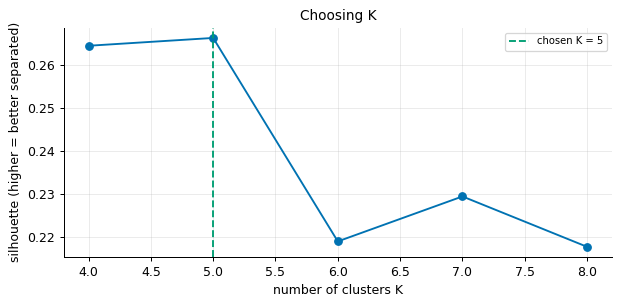

In [4]:
K_RANGE = [3] if gd.SMOKE else [4, 5, 6, 7, 8]
SILHOUETTE_SAMPLE = 5_000          # series sampled for the silhouette, for speed


def silhouette_sweep() -> pd.DataFrame:
    """Silhouette score of k-means for each K in ``K_RANGE``."""
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=bc.RANDOM_SEED).fit(scaled)
        sample = min(SILHOUETTE_SAMPLE, len(scaled))
        score = silhouette_score(scaled, km.labels_, sample_size=sample,
                                 random_state=bc.RANDOM_SEED)
        rows.append({"k": k, "silhouette": score, "inertia": km.inertia_})
    return pd.DataFrame(rows)


sweep = gd.cached("06_silhouette", silhouette_sweep)
best_k = int(sweep.loc[sweep["silhouette"].idxmax(), "k"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(sweep["k"], sweep["silhouette"], "o-")
ax.axvline(best_k, color=gplt.COLOURS["good"], ls="--", label=f"chosen K = {best_k}")
ax.set(xlabel="number of clusters K", ylabel="silhouette (higher = better separated)",
       title="Choosing K")
ax.legend()
fig.tight_layout()
plt.show()

The final clustering is cached, so every later run uses the same labels. Clusters are numbered
from the highest-selling (0) to the lowest.

In [5]:
def make_clusters() -> pd.DataFrame:
    """K-means labels for every training series, renumbered by mean volume (0 = highest)."""
    km = KMeans(n_clusters=best_k, n_init=10, random_state=bc.RANDOM_SEED).fit(scaled)
    out = features.assign(raw=km.labels_)
    order = out.groupby("raw")["log_mean_units"].mean().sort_values(ascending=False).index
    out["cluster"] = out["raw"].map({raw: i for i, raw in enumerate(order)})
    return out.drop(columns="raw").assign(k=best_k)


clusters = gd.cached("06_clusters", make_clusters)
cluster_of = clusters.set_index("unique_id")["cluster"]
info["cluster"] = cluster_of

### Cluster profiles

These are the feature means per cluster, with each cluster's size, how many scored series fall
in it and its most common sales class. It is worth giving each cluster a plain name before you
go on (e.g. "steady fast sellers", "mostly zeros"), as it makes the results easier to read.

In [6]:
profile = clusters.groupby("cluster")[FEATURES].mean()
profile.insert(0, "series", clusters.groupby("cluster").size())
profile.insert(1, "scored", info.loc[eval_ids].groupby("cluster").size())
profile.insert(2, "main_class", info.groupby("cluster")["sale_class"].agg(
    lambda s: s.value_counts().index[0]))
profile.round(2)

,series,scored,main_class,log_mean_units,zero_share,log_cv2_nonzero,promo_share,discount_share,recent_trend,yearly_acf
cluster,,,,,,,,,,
0,2475,280,J,7.76,0.07,0.11,0.83,0.05,0.01,0.16
1,3335,410,J,7.27,0.09,0.54,0.27,0.25,0.04,0.28
2,7164,806,J,6.75,0.07,0.16,0.08,0.04,-0.35,0.15
3,1926,196,J,6.55,0.35,0.26,0.16,0.07,4.85,-0.01
4,2341,308,J,2.59,0.70,0.38,0.04,0.03,1.02,0.03


## 4. The rule, written before the results

The three arms are scored once on the test window. A cluster arm **beats pooled** only if its
median RMSSE is lower by more than the 02 noise floor; otherwise pooled stays, because it is one
model instead of several. As the rule reads the test window, it only reports whether
clustering is worth pursuing, and does not change the model that later notebooks use.

## 5. Arm 1: pooled + cluster static

This is the selected model's data, with one one-hot cluster column per cluster added to the
statics. The oversampled training data keeps each series' cluster.

In [7]:
def with_cluster_statics(data: gd.NixtlaData, cluster_of: pd.Series) -> gd.NixtlaData:
    """``data`` with one-hot cluster statics; copies take their original series' cluster."""
    ids = data.static_df[["unique_id"]].copy()
    original = ids["unique_id"].str.split(gp.COPY_TAG).str[0]
    ids["cluster"] = original.map(cluster_of)
    onehot = pd.get_dummies(ids["cluster"], prefix="cluster").astype("float32")
    static = data.static_df.merge(pd.concat([ids[["unique_id"]], onehot], axis=1),
                                  on="unique_id")
    return replace(data, static_df=static, stat_exog=data.stat_exog + list(onehot.columns))


static_data = with_cluster_statics(data, cluster_of)


def cluster_static_model(seed):
    return gd.build_nbeatsx(params, static_data, cfg["max_steps"], seed, "GFM_cluster_static")


static_runs = gd.fit_seeds(cluster_static_model, static_data, "06_cluster_static")
static_fcst = gd.seed_forecasts(static_runs)

2026-11-26 16:49:36,239	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-26 16:49:36,444	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


## 6. Arm 2: one model per cluster

Each cluster gets its own model, trained only on its own series. The step budget is scaled to
the cluster's size (`gd.scaled_max_steps`, ≈174 visits per series, §3), so a small cluster is
not over-trained. Clusters without a scored series are skipped, and the forecasts are then
stacked into one frame.

In [8]:
def cluster_subset(data: gd.NixtlaData, ids: set) -> gd.NixtlaData:
    """``data`` restricted to the series in ``ids`` and their oversampled copies."""
    keep = {u for u in data.fit_df["unique_id"].unique() if u.split(gp.COPY_TAG)[0] in ids}
    fit_df = data.fit_df[data.fit_df["unique_id"].isin(keep)]
    static = data.static_df[data.static_df["unique_id"].isin(set(fit_df["unique_id"]))]
    return replace(data, fit_df=fit_df, predict_df=gd.only(data.predict_df, ids),
                   futr_df=gd.only(data.futr_df, ids), static_df=static)


per_cluster_fcst = []
per_cluster_runs = {}
cluster_steps = {}
for k in sorted(clusters["cluster"].unique()):
    ids = set(clusters.loc[clusters["cluster"] == k, "unique_id"])
    if not ids & set(eval_ids):
        continue
    sub = cluster_subset(data, ids)
    steps = gd.scaled_max_steps(sub.fit_df["unique_id"].nunique(),
                                batch_size=params.get("batch_size", 256))
    cluster_steps[int(k)] = steps

    def per_cluster_model(seed, sub=sub, steps=steps):
        return gd.build_nbeatsx(params, sub, steps, seed, "GFM_per_cluster")

    with bc.Timer() as t:
        runs = gd.fit_seeds(per_cluster_model, sub, f"06_per_cluster_c{k}")
    per_cluster_runs[int(k)] = runs
    per_cluster_fcst.append(gd.seed_forecasts(runs))
    print(f"cluster {k}: {sub.fit_df['unique_id'].nunique():,} series incl. copies, "
          f"{steps:,} steps, {t.seconds:.0f}s")
per_cluster_fcst = pd.concat(per_cluster_fcst, ignore_index=True)

cluster 0: 4,600 series incl. copies, 3,126 steps, 0s


cluster 1: 17,898 series incl. copies, 12,165 steps, 0s


cluster 2: 11,739 series incl. copies, 7,978 steps, 0s


cluster 3: 3,471 series incl. copies, 2,359 steps, 0s


cluster 4: 2,341 series incl. copies, 2,000 steps, 0s


## 7. Scores on the test window

Here are the median and mean RMSSE for each arm, with the spread of the seed medians for the
two new arms.

In [9]:
pooled = gd.selected_forecasts(cfg).rename(columns={"GFM_selected": "GFM_pooled"})
arms = {"GFM_pooled": "GFM_pooled", "GFM_cluster_static": "GFM_cluster_static_mean",
        "GFM_per_cluster": "GFM_per_cluster_mean"}
both = (pooled.merge(static_fcst, on=["unique_id", "ds"])
        .merge(per_cluster_fcst, on=["unique_id", "ds"]))
metrics = gd.score(both, test, train)
rmsse_all = gd.per_series(metrics)
rmsse = rmsse_all[list(arms.values())].rename(columns={v: k for k, v in arms.items()})

seed_rows = []
for arm in ("GFM_cluster_static", "GFM_per_cluster"):
    seed_cols = [c for c in rmsse_all.columns if c.startswith(f"{arm}_s")]
    for col in seed_cols:
        seed_rows.append({"arm": arm, "seed": col.rsplit("_s", 1)[-1],
                          "median_rmsse": rmsse_all[col].median()})
seed_table = pd.DataFrame(seed_rows)
summary = pd.DataFrame({"median_rmsse": rmsse.median(), "mean_rmsse": rmsse.mean()})
seed_range = seed_table.groupby("arm")["median_rmsse"]
summary["seed_spread"] = seed_range.max() - seed_range.min()
summary.round(4)

,median_rmsse,mean_rmsse,seed_spread
GFM_pooled,0.5200,1.0784,NaN
GFM_cluster_static,0.5263,1.0919,0.0070
GFM_per_cluster,0.5417,1.0980,0.0111


In [10]:
board = both[["unique_id", "ds", "GFM_cluster_static_mean", "GFM_per_cluster_mean"]]
board = board.rename(columns={"GFM_cluster_static_mean": "GFM_cluster_static",
                              "GFM_per_cluster_mean": "GFM_per_cluster"})
per_cluster_seconds = 0.0
for runs in per_cluster_runs.values():
    per_cluster_seconds += gd.summaries(runs)["fit_seconds"].mean()
fit_seconds = {"GFM_cluster_static": gd.summaries(static_runs)["fit_seconds"].mean(),
               "GFM_per_cluster": per_cluster_seconds}
gd.save_forecasts(board, "06_clusters")
gd.record(board, test, train, lab=f"06 clusters ({len(gd.SEEDS)}-seed mean)",
          fit_seconds=fit_seconds,
          notes="per seed; per cluster = sum over clusters")
gd.median_board("06")

,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,GFM_clean_floor,0.519,2.431,21.871,1999,05c clean + floor (3-seed mean),344.533
1,GFM_clean_floor_clip,0.520,1.078,0.399,1999,"05c clean + floor + clip, capped (3-seed mean)",357.533
2,GFM_floor,0.523,1.488,6.985,1999,05c scaler floor (3-seed mean),362.700
3,GFM_cluster_static,0.526,1.092,0.532,1999,06 clusters (3-seed mean),398.533
4,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
5,NBEATSx_B_cpi_mean,0.540,1.076,0.263,1999,04 price arms (3-seed mean),522.767
6,GFM_per_cluster,0.542,1.098,0.242,1999,06 clusters (3-seed mean),836.467
7,GFM_synthetic,0.546,1.768,0.265,1999,05b synthetic (3-seed mean),361.200
8,GFM_selected,0.546,1.067,0.257,1999,05 selected (3-seed mean),379.767
9,GFM_clean,0.551,2.778,0.266,1999,05c clean (3-seed mean),361.200


### Reading the result

* Median RMSSE first: is either gain over pooled bigger than the noise floor (≈ 0.005)? If
  not, it is a tie. Here neither arm gains: cluster static ≈ 0.526 and per cluster ≈ 0.542,
  against pooled ≈ 0.520 (05c's cleaned-price model with the scaler floor and input clip).
* The pooled mean (≈ 1.72) is higher than the arms' (≈ 1.09–1.10) because of one seed's
  blow-up on a best seller (`6653_S1`, 05c). The board here is not capped, whereas 08 and 11
  cap every item at 3× its largest training week.
* Compare each arm's seed spread with its gain. A gain smaller than the spread could vanish
  with a new seed.

*Exact numbers vary with seed and hardware.*

### Marginal wins over pooled (F4)

This shows the share of series won by class (by count and by volume), the spread of gains,
and one dot per series. A win share near 0.5 everywhere means the arms are interchangeable.

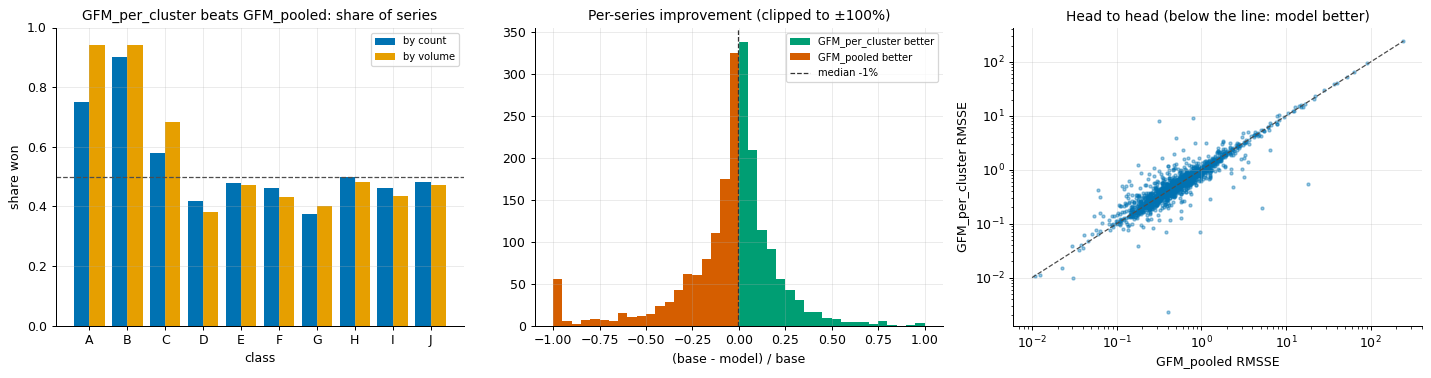

,win_share,win_share_volume,n
sale_class,,,
A,0.750,0.942,4.0
B,0.900,0.941,10.0
C,0.579,0.682,19.0
D,0.419,0.382,31.0
E,0.478,0.472,46.0
F,0.463,0.430,67.0
G,0.375,0.400,96.0
H,0.500,0.481,148.0
I,0.463,0.435,259.0


In [11]:
gplt.plot_wins(rmsse, info, model="GFM_per_cluster", baseline="GFM_pooled")

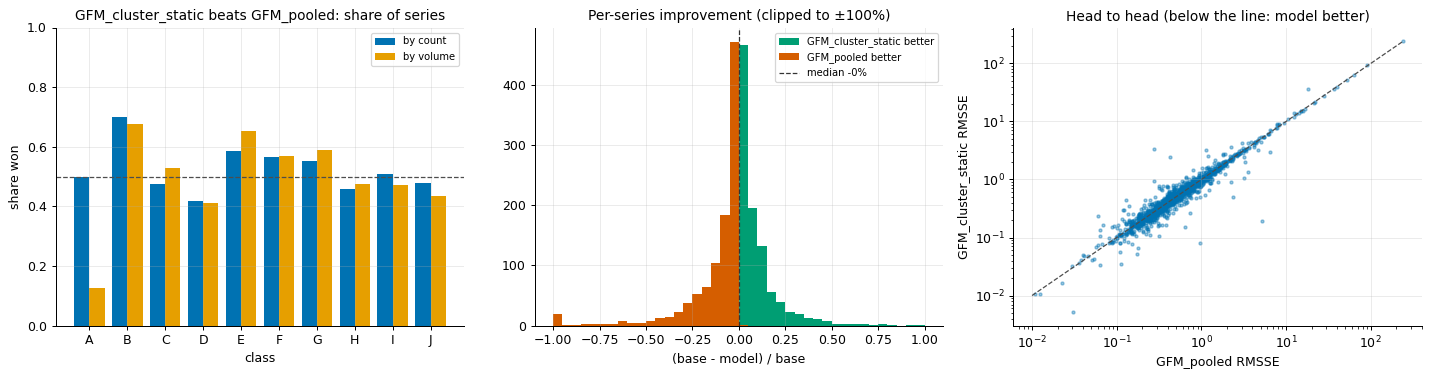

,win_share,win_share_volume,n
sale_class,,,
A,0.500,0.127,4.0
B,0.700,0.675,10.0
C,0.474,0.529,19.0
D,0.419,0.412,31.0
E,0.587,0.654,46.0
F,0.567,0.569,67.0
G,0.552,0.590,96.0
H,0.459,0.474,148.0
I,0.510,0.471,259.0


In [12]:
gplt.plot_wins(rmsse, info, model="GFM_cluster_static", baseline="GFM_pooled")

### Where each arm wins: by cluster and by sales class

There are two heatmaps. Rows are arms, columns are clusters (then sales classes), and each
cell is the median RMSSE; greener is better. Read **down a column**, as the colour change
between arms is the effect. Reading across mixes in how hard each group is to forecast, which
is not the point here.

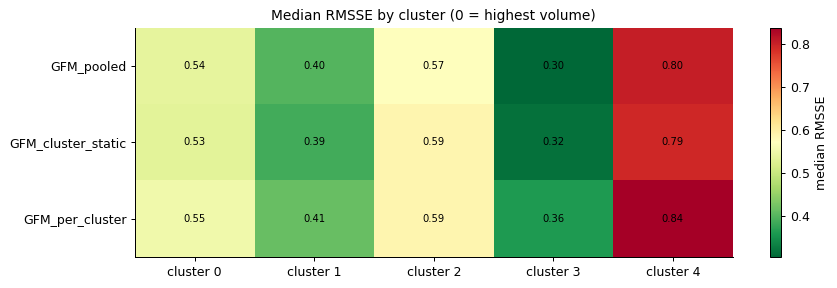

In [13]:
by_cluster = rmsse.join(info["cluster"]).groupby("cluster")[list(arms)].median().T
gplt.plot_heatmap(by_cluster.rename(columns=lambda c: f"cluster {c}"),
                  "Median RMSSE by cluster (0 = highest volume)", label="median RMSSE",
                  figsize=(10, 0.5 * len(arms) + 1.8))

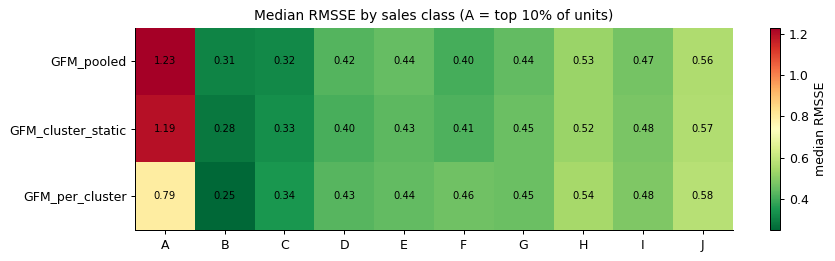

In [14]:
gplt.plot_class_heatmap(rmsse, info)

The whole distribution (F2) shows per-series RMSSE as a histogram, a cumulative curve and a
box plot by class. A median gain that comes from the tail shows up here.

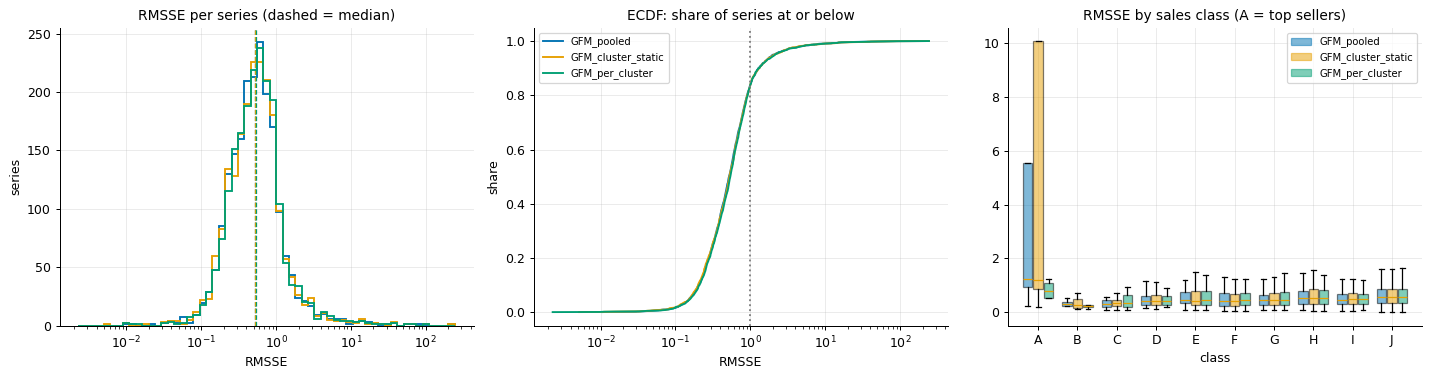

In [15]:
gplt.plot_error_dist(rmsse, info)

## 8. Apply the rule

Here is the gain of each cluster arm over pooled, against the noise floor. The config records
the winner for notebook 10 to report.

In [16]:
pooled_median = summary.loc["GFM_pooled", "median_rmsse"]
gains = pooled_median - summary["median_rmsse"].drop("GFM_pooled")
beats_pooled = gains[gains > noise_floor]
winner = beats_pooled.idxmax() if len(beats_pooled) else "GFM_pooled"
print(f"gain over pooled (median RMSSE): {gains.round(4).to_dict()} | "
      f"noise floor {noise_floor} | winner: {winner}")

gain over pooled (median RMSSE): {'GFM_cluster_static': -0.0063, 'GFM_per_cluster': -0.0218} | noise floor 0.004767416900440408 | winner: GFM_pooled


In [17]:
gd.save_config("06_clusters", {
    "selected_from": pooled_name,
    "features": FEATURES,
    "k_range": K_RANGE,
    "k": best_k,
    "silhouette": sweep.round(4).to_dict("records"),
    "cluster_sizes": clusters["cluster"].value_counts().sort_index().to_dict(),
    "cluster_max_steps": cluster_steps,
    "seeds": gd.SEEDS,
    "median_rmsse": summary["median_rmsse"].round(4).to_dict(),
    "mean_rmsse": summary["mean_rmsse"].round(4).to_dict(),
    "seed_medians": seed_table.round(4).to_dict("records"),
    "median_rmsse_by_cluster": by_cluster.round(4).to_dict("index"),
    "noise_floor": noise_floor,
    "rule": "a cluster arm wins only if its test median RMSSE beats pooled by > noise floor",
    "winner": winner,
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/06_clusters.json')

## Discussion

* Per-cluster models see fewer series each. Is the smallest cluster where splitting costs
  most?
* If the cluster static does no better than pooled, the model may already infer the group from
  the statics and the history it sees. What would convince you otherwise?
* The features describe demand, not price response. Would clusters built on discount depth and
  lift group the series differently?

**Try it:** add `log_mean_price` or the department one-hot to `FEATURES`, delete
`06_clusters.parquet` and `06_silhouette.parquet`, and rerun with `GD_TRAIN=1`.